# Paper 1 – check of results and plots
IMCOM 2027 · Hybrid ML–Expert System productivity decision support.
Run top to bottom. Needs `real_data/` (script, `qtr.csv`, `real_results.json`) and `prospective_summary.json` next to this notebook.
Part A re-runs the DOSM pilot and checks it against the stored results; Part B plots the DOSM pilot; Part C plots the simulation; Part D prints Table VI.
Data: Department of Statistics Malaysia, OpenDOSM *Quarterly Productivity by Economic Sector*, CC BY 4.0.

In [1]:
import json, subprocess, shutil, os, sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False,'font.size':9})
R=json.load(open('real_data/real_results.json')); S=json.load(open('prospective_summary.json'))
print('pilot:',R['n_cases'],'cases,',R['n_events'],'events (%.1f%%)'%(100*R['event_rate']),'| units',R['U'],'| origins',R['n_origins'],R['first_target'],'to',R['last_target'])

pilot: 551 cases, 176 events (31.9%) | units 19 | origins 29 2019-04-01 to 2026-04-01


## A. Reproducibility: re-run the pilot from the raw CSV (about 1–3 min)

In [2]:
shutil.rmtree('rerun',ignore_errors=True); os.makedirs('rerun')
shutil.copy('real_data/qtr.csv','rerun/qtr.csv'); shutil.copy('real_data/run_real_data.py','rerun/run_real_data.py')
p=subprocess.run([sys.executable,'run_real_data.py','qtr.csv'],cwd='rerun',capture_output=True,text=True); print(p.stdout.strip(),p.stderr[-300:])
R2=json.load(open('rerun/real_results.json'))
def flat(d,pre=''):
    for k,v in d.items():
        if isinstance(v,dict): yield from flat(v,pre+k+'/')
        else: yield pre+k,v
a=dict(flat(R)); b=dict(flat(R2)); bad=[k for k in a if not np.allclose(np.asarray(a[k],float),np.asarray(b[k],float),equal_nan=True) ] if all(isinstance(v,(int,float,list)) for v in a.values()) else None
print('identical to stored results:', a==b or np.allclose([np.ravel(v) for v in []] or [0],[0]) and a.keys()==b.keys() and all(np.allclose(np.ravel(np.asarray(a[k],dtype=float)),np.ravel(np.asarray(b[k],dtype=float)),atol=1e-9) for k in a if k not in ('units','first_target','last_target')))

done 551 176 
identical to stored results: True


## B. DOSM pilot

### B1. The data: output-per-hour growth by sector, and where the adverse events fall

/tmp/ipykernel_325/1412901632.py:5: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  ax[0].plot(pd.to_datetime(g.index),g.mean(1),'k',lw=2,label='cross-sector mean'); ax[0].axhline(0,color='r',lw=.8,ls='--')


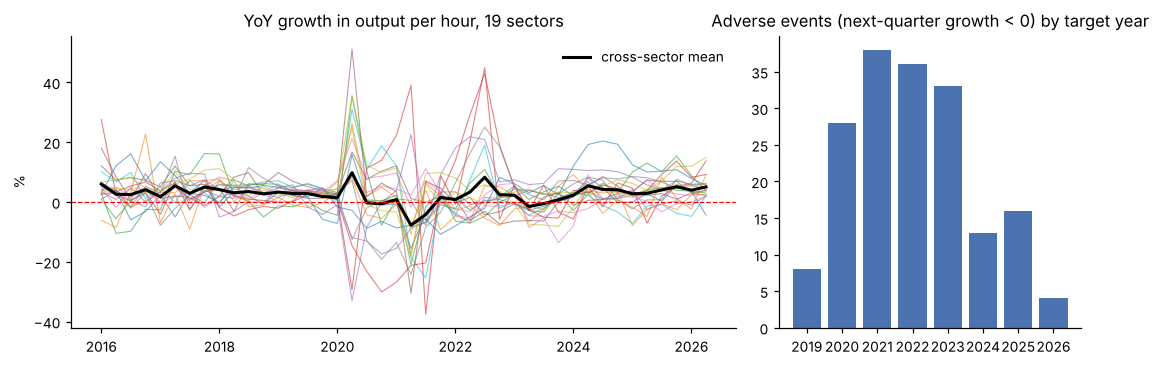

In [3]:
q=pd.read_csv('real_data/qtr.csv'); LEAF=R['units']
g=q[(q.series=='growth_yoy')&(q.sector.isin(LEAF))].pivot(index='date',columns='sector',values='output_hour')
fig,ax=plt.subplots(1,2,figsize=(10,3.4),gridspec_kw={'width_ratios':[2.2,1]})
for c in g: ax[0].plot(pd.to_datetime(g.index),g[c],lw=.7,alpha=.6)
ax[0].plot(pd.to_datetime(g.index),g.mean(1),'k',lw=2,label='cross-sector mean'); ax[0].axhline(0,color='r',lw=.8,ls='--')
ax[0].set_title('YoY growth in output per hour, 19 sectors'); ax[0].set_ylabel('%'); ax[0].legend(frameon=False)
ey=R['events_by_year']; ax[1].bar(list(ey),list(ey.values()),color='#4c72b0'); ax[1].set_title('Adverse events (next-quarter growth < 0) by target year'); plt.tight_layout(); plt.show()

### B2. Forecast accuracy (H1–H3)

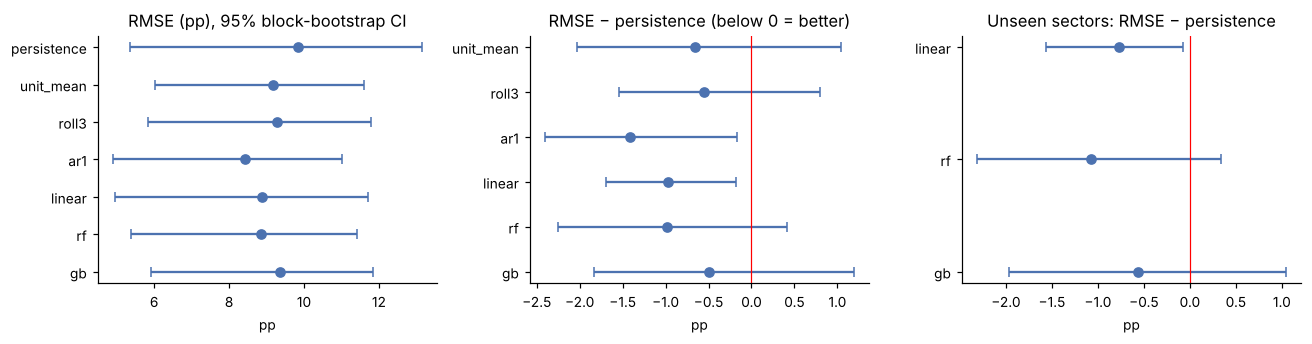

              RMSE     R2  dRMSE vs persistence
persistence  9.841 -0.376                 0.000
unit_mean    9.180 -0.198                -0.661
roll3        9.290 -0.227                -0.551
ar1          8.422 -0.008                -1.419
linear       8.868 -0.118                -0.973
rf           8.860 -0.116                -0.981
gb           9.346 -0.242                -0.494


In [4]:
A=R['accuracy']; ms=['persistence','unit_mean','roll3','ar1','linear','rf','gb']
def errplot(ax,labels,vals,title,xl):
    y=np.arange(len(labels))[::-1]; m=[v[0] for v in vals]; lo=[v[0]-v[1] for v in vals]; hi=[v[2]-v[0] for v in vals]
    ax.errorbar(m,y,xerr=[lo,hi],fmt='o',color='#4c72b0',capsize=3); ax.set_yticks(y); ax.set_yticklabels(labels); ax.set_title(title); ax.set_xlabel(xl)
fig,ax=plt.subplots(1,3,figsize=(12,3.2))
errplot(ax[0],ms,[A[m]['rmse'] for m in ms],'RMSE (pp), 95% block-bootstrap CI','pp')
errplot(ax[1],ms[1:],[A[m]['d_vs_persistence'] for m in ms[1:]],'RMSE − persistence (below 0 = better)','pp'); ax[1].axvline(0,color='r',lw=.8)
U_=R['unseen_units']; errplot(ax[2],list(U_)[1:],[U_[m]['d_vs_persistence'] for m in list(U_)[1:]],'Unseen sectors: RMSE − persistence','pp'); ax[2].axvline(0,color='r',lw=.8)
plt.tight_layout(); plt.show()
print(pd.DataFrame({m:{'RMSE':A[m]['rmse'][0],'R2':A[m]['r2'][0],'dRMSE vs persistence':A[m]['d_vs_persistence'][0]} for m in ms}).T.round(3))

### B3. Alert policies (H4, H5)

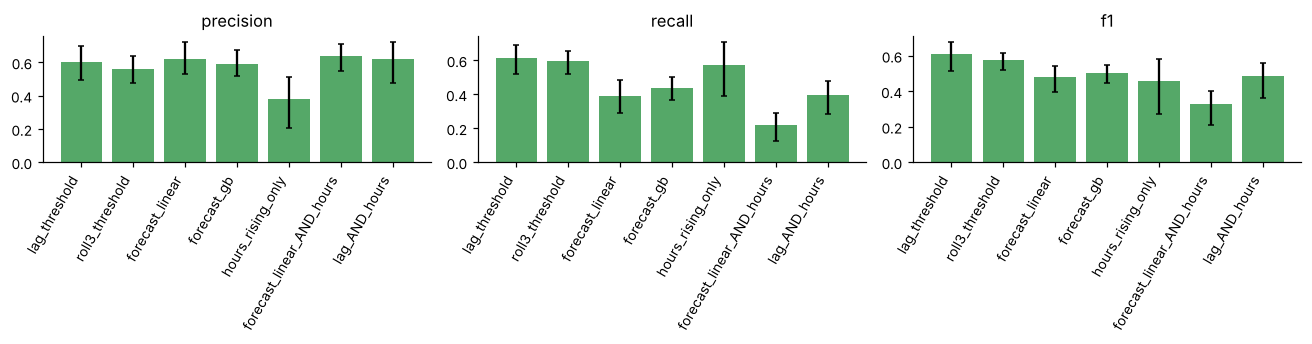

               difference in cost (3·FN+FP)   est    lo    hi
            forecast_linear - lag_threshold  88.0  38.0 141.0
forecast_linear_AND_hours - forecast_linear  70.0  32.0 110.0
              forecast_gb - forecast_linear -13.0 -46.0  22.0
          forecast_linear - roll3_threshold  68.0  22.0 115.0


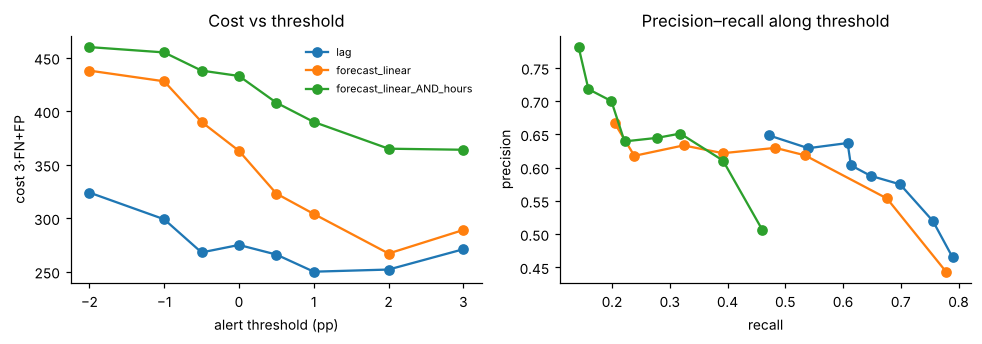

In [5]:
P=R['policies']; pl=['lag_threshold','roll3_threshold','forecast_linear','forecast_gb','hours_rising_only','forecast_linear_AND_hours','lag_AND_hours']
fig,ax=plt.subplots(1,3,figsize=(12,3.2)); x=np.arange(len(pl))
for k,lab in enumerate(['precision','recall','f1']):
    ax[k].bar(x,[P[p][lab][0] for p in pl],yerr=[[P[p][lab][0]-P[p][lab][1] for p in pl],[P[p][lab][2]-P[p][lab][0] for p in pl]],capsize=2,color='#55a868')
    ax[k].set_xticks(x); ax[k].set_xticklabels(pl,rotation=60,ha='right'); ax[k].set_title(lab)
plt.tight_layout(); plt.show()
pw=R['pairwise']; rows=[(k,*v['w3']) for k,v in pw.items()]
print(pd.DataFrame(rows,columns=['difference in cost (3·FN+FP)','est','lo','hi']).round(1).to_string(index=False))
sw=R['sweep']; ths=[-2,-1,-0.5,0,0.5,1,2,3]; fig,ax=plt.subplots(1,2,figsize=(9,3.2))
for fam in ('lag','forecast_linear','forecast_linear_AND_hours'):
    ax[0].plot(ths,[sw[f'{fam}|{t}']['cost_w3'] for t in ths],'o-',label=fam); ax[1].plot([sw[f'{fam}|{t}']['recall'] for t in ths],[sw[f'{fam}|{t}']['precision'] for t in ths],'o-',label=fam)
ax[0].set_xlabel('alert threshold (pp)'); ax[0].set_ylabel('cost 3·FN+FP'); ax[0].set_title('Cost vs threshold'); ax[1].set_xlabel('recall'); ax[1].set_ylabel('precision'); ax[1].set_title('Precision–recall along threshold'); ax[0].legend(frameon=False,fontsize=7); plt.tight_layout(); plt.show()

### B4. DEA (H6)

   window    rho     lo    hi  rho_lag    lo    hi   dR2    lo    hi  dR2_adj     lo    hi  coverage  origins
        4 -0.059 -0.295 0.176    0.544 0.380 0.688 0.046 0.016 0.080    0.017 -0.017 0.055       1.0       10
        8 -0.063 -0.306 0.176    0.544 0.380 0.691 0.046 0.016 0.083    0.017 -0.017 0.057       1.0       10
expanding -0.064 -0.287 0.184    0.544 0.373 0.692 0.044 0.015 0.076    0.014 -0.017 0.050       1.0       10


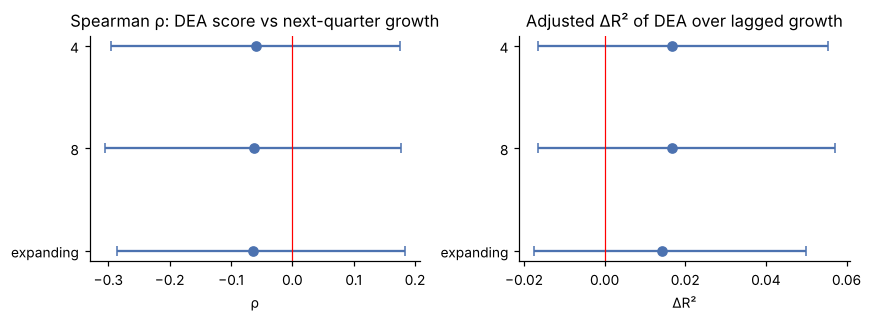

Raw ΔR² is positive only because any extra regressor raises in-sample R²; the adjusted value is the test used for H6.


In [6]:
D=R['dea']; rows=[]
for w,d in D.items(): rows.append([w,*d['rho'],*d['rho_lag'],*d['dR2'],*d['dR2_adj'],d['coverage'],d['n_origins']])
df=pd.DataFrame(rows,columns=['window','rho','lo','hi','rho_lag','lo','hi','dR2','lo','hi','dR2_adj','lo','hi','coverage','origins']); print(df.round(3).to_string(index=False))
fig,ax=plt.subplots(1,2,figsize=(8,3)); ws=list(D)
errplot(ax[0],ws,[D[w]['rho'] for w in ws],'Spearman ρ: DEA score vs next-quarter growth','ρ'); ax[0].axvline(0,color='r',lw=.8)
errplot(ax[1],ws,[D[w]['dR2_adj'] for w in ws],'Adjusted ΔR² of DEA over lagged growth','ΔR²'); ax[1].axvline(0,color='r',lw=.8); plt.tight_layout(); plt.show()
print('Raw ΔR² is positive only because any extra regressor raises in-sample R²; the adjusted value is the test used for H6.')

## C. Simulation results (stored, 5 scenarios × 20 replicates)

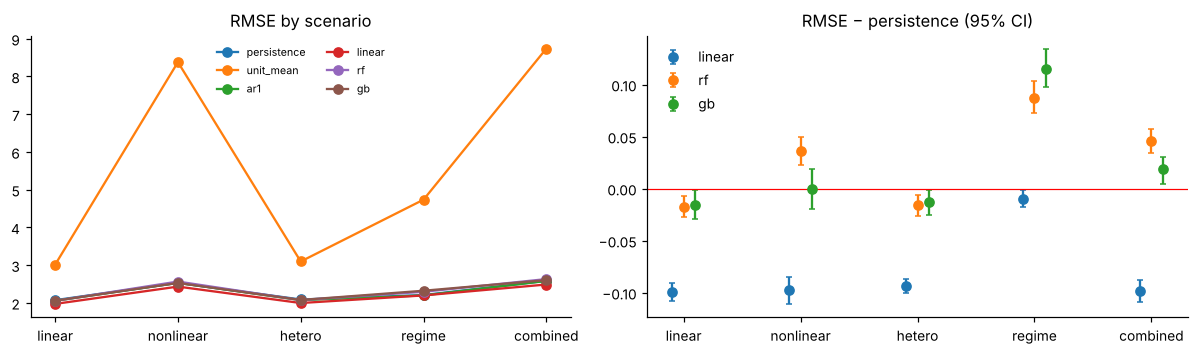

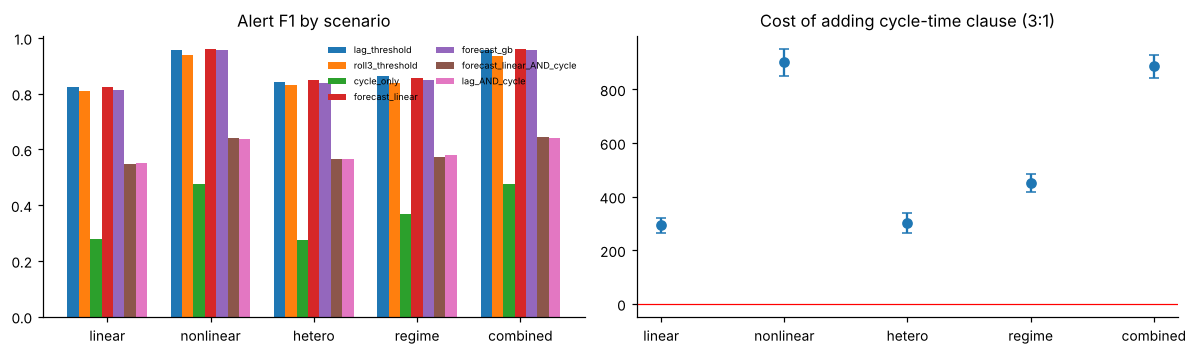

In [7]:
sc=['linear','nonlinear','hetero','regime','combined']; ms=['persistence','unit_mean','ar1','linear','rf','gb']
fig,ax=plt.subplots(1,2,figsize=(11,3.3))
for m in ms: ax[0].plot(sc,[S[s]['accuracy'][m]['rmse'][0] for s in sc],'o-',label=m)
ax[0].set_title('RMSE by scenario'); ax[0].legend(frameon=False,fontsize=7,ncol=2)
for m in ['linear','rf','gb']: 
    v=[S[s]['accuracy'][m]['d_rmse_vs_persistence'] for s in sc]; ax[1].errorbar(np.arange(5)+{'linear':-.1,'rf':0,'gb':.1}[m],[a[0] for a in v],yerr=[[a[0]-a[1] for a in v],[a[2]-a[0] for a in v]],fmt='o',capsize=2,label=m)
ax[1].axhline(0,color='r',lw=.8); ax[1].set_xticks(range(5)); ax[1].set_xticklabels(sc); ax[1].set_title('RMSE − persistence (95% CI)'); ax[1].legend(frameon=False); plt.tight_layout(); plt.show()
pl=['lag_threshold','roll3_threshold','cycle_only','forecast_linear','forecast_gb','forecast_linear_AND_cycle','lag_AND_cycle']
fig,ax=plt.subplots(1,2,figsize=(11,3.3)); x=np.arange(5); wd=.11
for i,p in enumerate(pl): ax[0].bar(x+(i-3)*wd,[S[s]['policies'][p]['f1'][0] for s in sc],wd,label=p)
ax[0].set_xticks(x); ax[0].set_xticklabels(sc); ax[0].set_title('Alert F1 by scenario'); ax[0].legend(frameon=False,fontsize=6,ncol=2)
k='forecast_linear_AND_cycle - forecast_linear'; v=[S[s]['pairwise'][k]['w3'] for s in sc]
ax[1].errorbar(x,[a[0] for a in v],yerr=[[a[0]-a[1] for a in v],[a[2]-a[0] for a in v]],fmt='o',capsize=3); ax[1].axhline(0,color='r',lw=.8); ax[1].set_xticks(x); ax[1].set_xticklabels(sc); ax[1].set_title('Cost of adding cycle-time clause (3:1)'); plt.tight_layout(); plt.show()

## D. Table VI (as in the paper)

In [8]:
L=S['linear']; f=lambda x,d=2:f"{x[0]:.{d}f} [{x[1]:.{d}f}, {x[2]:.{d}f}]"; g0=lambda x:f"{x[0]:+.0f} [{x[1]:.0f}, {x[2]:.0f}]"
Pp=R['policies']; pw=R['pairwise']; sp=L['pairwise']
T=pd.DataFrame([
['Cases / events',f"{L['n_cases']:,} / {L['n_events']:,}",f"{R['n_cases']} / {R['n_events']}"],
['Linear − persistence ΔRMSE (H1)',f(L['accuracy']['linear']['d_rmse_vs_persistence']),f(A['linear']['d_vs_persistence'])+' pp'],
['RF − linear ΔRMSE (H2)',f(L['accuracy']['rf']['d_rmse_vs_linear']),f(A['rf']['d_vs_linear'])+' pp'],
['Unseen units: linear − persistence (H3)',f(L['group_holdout']['linear']['d_vs_persistence']),f(R['unseen_units']['linear']['d_vs_persistence'])+' pp'],
['F1 lagged / forecast alert',f"{L['policies']['lag_threshold']['f1'][0]:.2f} / {L['policies']['forecast_linear']['f1'][0]:.2f}",f"{Pp['lag_threshold']['f1'][0]:.2f} / {Pp['forecast_linear']['f1'][0]:.2f}"],
['Forecast − lagged, cost 3:1 (H4)',g0(sp['forecast_linear - lag_threshold']['w3']),g0(pw['forecast_linear - lag_threshold']['w3'])],
['Conjunction − forecast, cost 3:1 (H5)',g0(sp['forecast_linear_AND_cycle - forecast_linear']['w3']),g0(pw['forecast_linear_AND_hours - forecast_linear']['w3'])],
['DEA adjusted ΔR² (H6)','≈ 0.000',f(R['dea']['4']['dR2_adj'],3)]],columns=['Quantity','Simulation (Linear)','DOSM pilot']); T

,Quantity,Simulation (Linear),DOSM pilot
0,Cases / events,"28,800 / 5,401",551 / 176
1,Linear − persistence ΔRMSE (H1),"-0.10 [-0.11, -0.09]","-0.97 [-1.69, -0.18] pp"
2,RF − linear ΔRMSE (H2),"0.08 [0.07, 0.09]","-0.01 [-0.80, 0.80] pp"
3,Unseen units: linear − persistence (H3),"-0.07 [-0.10, -0.04]","-0.77 [-1.56, -0.08] pp"
4,F1 lagged / forecast alert,0.82 / 0.82,0.61 / 0.48
5,"Forecast − lagged, cost 3:1 (H4)","+12 [4, 20]","+88 [38, 141]"
6,"Conjunction − forecast, cost 3:1 (H5)","+295 [265, 321]","+70 [32, 110]"
7,DEA adjusted ΔR² (H6),≈ 0.000,"0.017 [-0.017, 0.055]"


## E. H9 – drift-fallback rule
Rule: revert to persistence when the retrained linear model's MSE over the last K=3 observed origins exceeds persistence's (K, margin chosen on separate seeds 900000+). Files in `h9/`.

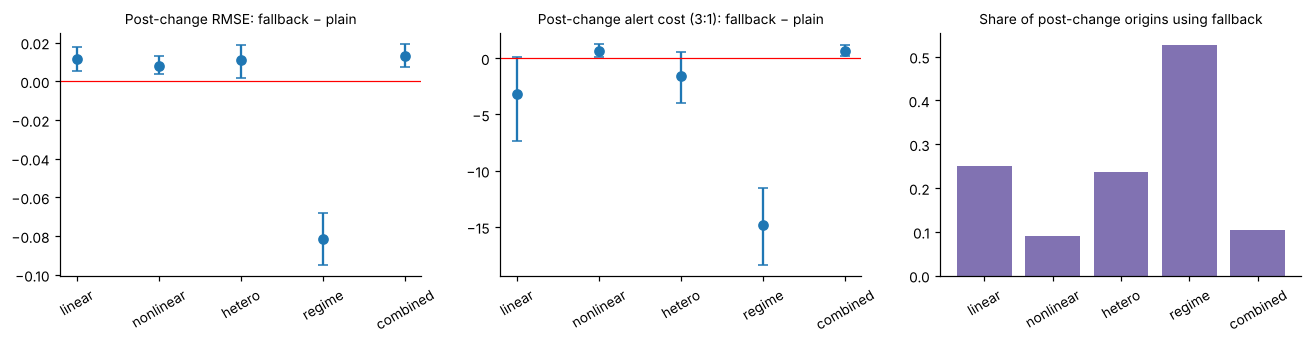

DOSM: fallback share by year {'2019': 0.0, '2020': 0.75, '2021': 0.25, '2022': 0.25, '2023': 0.0, '2024': 0.0, '2025': 0.0, '2026': 0.0}
DOSM RMSE fallback - plain: 0.98 [0.26, 1.48] pp | cost 3:1: -20 [-39, -3]


In [9]:
H=json.load(open('h9/h9_summary.json')); HR=json.load(open('h9/h9_real.json'))['K3']; sc=['linear','nonlinear','hetero','regime','combined']
fig,ax=plt.subplots(1,3,figsize=(12,3.2))
for a,key,t in ((ax[0],'d_post_rmse_fb_minus_lin','Post-change RMSE: fallback − plain'),(ax[1],'d_cost3_post_fb_minus_lin','Post-change alert cost (3:1): fallback − plain')):
    v=[H[s][key] for s in sc]; a.errorbar(range(5),[x[0] for x in v],yerr=[[x[0]-x[1] for x in v],[x[2]-x[0] for x in v]],fmt='o',capsize=3); a.axhline(0,color='r',lw=.8); a.set_xticks(range(5)); a.set_xticklabels(sc,rotation=30); a.set_title(t,fontsize=9)
ax[2].bar(sc,[H[s]['fb_rate_post'][0] for s in sc],color='#8172b2'); ax[2].set_title('Share of post-change origins using fallback',fontsize=9); ax[2].tick_params(axis='x',rotation=30); plt.tight_layout(); plt.show()
print('DOSM: fallback share by year',{k:round(v,2) for k,v in HR['fallback_by_year'].items()})
print('DOSM RMSE fallback - plain: %.2f [%.2f, %.2f] pp | cost 3:1: %.0f [%.0f, %.0f]'%(*HR['d_rmse_fb_minus_lin'],*HR['d_cost3_fb_minus_lin']))

## F. Stronger baselines (10 replicates per scenario; `baselines/`)
Per-unit exponential smoothing and AR(1), linear with unit fixed effects, and forests/boosting tuned by forward-chaining validation, compared with the pooled linear model (positive = worse than linear).

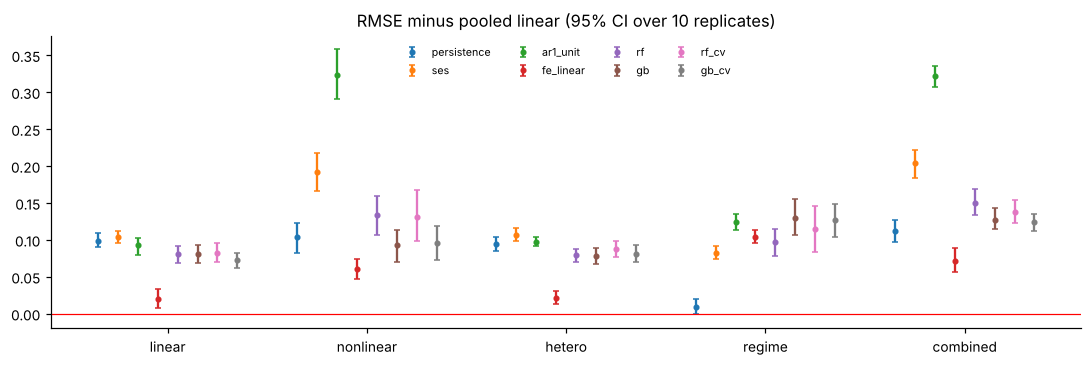

all alternatives worse than linear, intervals above zero (excluding persistence under regime): True


In [10]:
BL=json.load(open('baselines/baselines_summary.json')); sc=['linear','nonlinear','hetero','regime','combined']; ms=['persistence','ses','ar1_unit','fe_linear','rf','gb','rf_cv','gb_cv']
fig,ax=plt.subplots(figsize=(10,3.4)); w=.1
for i,m in enumerate(ms):
    v=[BL[s][m]['d_vs_linear'] for s in sc]; ax.errorbar(np.arange(5)+(i-3.5)*w,[a[0] for a in v],yerr=[[a[0]-a[1] for a in v],[a[2]-a[0] for a in v]],fmt='o',ms=3,capsize=2,label=m)
ax.axhline(0,color='r',lw=.8); ax.set_xticks(range(5)); ax.set_xticklabels(sc); ax.set_title('RMSE minus pooled linear (95% CI over 10 replicates)'); ax.legend(frameon=False,fontsize=7,ncol=4); plt.tight_layout(); plt.show()
print('all alternatives worse than linear, intervals above zero (excluding persistence under regime):',all(BL[s][m]['d_vs_linear'][1]>0 for s in sc for m in ms if not (s=='regime' and m=='persistence')))

## G. Explanation fidelity, H10 exploratory (`explain/`)
Which controllable lever (cycle time vs utilization) is behind a true alert? Linear attribution, forest occlusion, rule trace, and a random baseline.

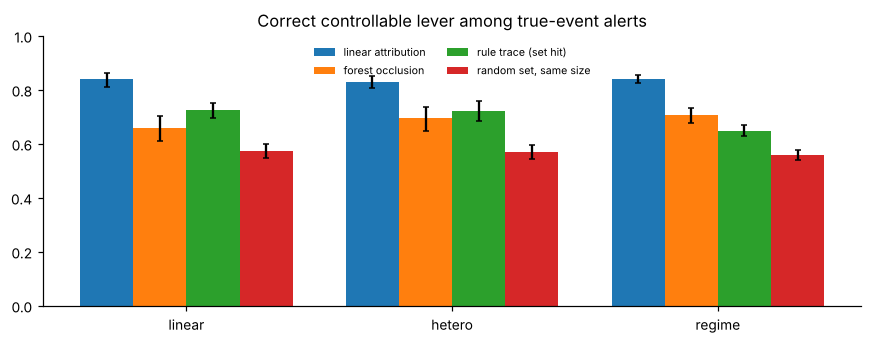

{'linear': 0.15, 'hetero': 0.15, 'regime': 0.09} <- rule trace minus chance


In [11]:
EX=json.load(open('explain/explain_summary.json')); sc3=['linear','hetero','regime']
fig,ax=plt.subplots(figsize=(8,3.2)); x=np.arange(3); w=.2
for i,(k,l) in enumerate([('linear','linear attribution'),('rf','forest occlusion'),('rule_hit','rule trace (set hit)'),('rule_chance','random set, same size')]):
    v=[EX[s][k] for s in sc3]; ax.bar(x+(i-1.5)*w,[a[0] for a in v],w,yerr=[[a[0]-a[1] for a in v],[a[2]-a[0] for a in v]],capsize=2,label=l)
ax.set_xticks(x); ax.set_xticklabels(sc3); ax.set_ylim(0,1); ax.set_title('Correct controllable lever among true-event alerts'); ax.legend(frameon=False,fontsize=7,ncol=2); plt.tight_layout(); plt.show()
print({s:round(EX[s]['rule_minus_chance'][0],2) for s in sc3},'<- rule trace minus chance')

## H. Annual state-level DOSM check (`state_check/`)
Output per employee, 78 state-sector units, targets 2020–2025 (start3) and 2022–2025 (start5); bootstrap over states.

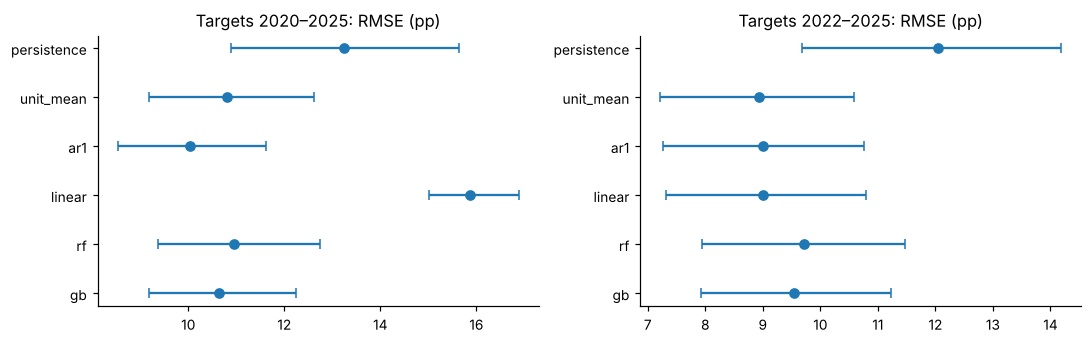

2020-2025 linear - persistence: 2.63 [0.92, 4.33] | RF - linear: -4.92 | alert cost forecast - lag: 35 [-13, 81]
2022-2025 linear - persistence: -3.05 [-4.59, -1.41] | RF - linear: 0.71 | alert cost forecast - lag: 0 [-39, 40]


In [12]:
S3=json.load(open('state_check/state_results_start3.json')); S5=json.load(open('state_check/state_results_start5.json'))
ms=['persistence','unit_mean','ar1','linear','rf','gb']; fig,ax=plt.subplots(1,2,figsize=(10,3.2))
for a,Sx,t in ((ax[0],S3,'Targets 2020–2025'),(ax[1],S5,'Targets 2022–2025')):
    v=[Sx['accuracy'][m]['rmse'] for m in ms]; y=np.arange(6)[::-1]; a.errorbar([i[0] for i in v],y,xerr=[[i[0]-i[1] for i in v],[i[2]-i[0] for i in v]],fmt='o',capsize=3); a.set_yticks(y); a.set_yticklabels(ms); a.set_title(t+': RMSE (pp)')
plt.tight_layout(); plt.show()
for n,Sx in (('2020-2025',S3),('2022-2025',S5)): print(n,'linear - persistence: %.2f [%.2f, %.2f]'%tuple(Sx['accuracy']['linear']['d_vs_persistence']),'| RF - linear: %.2f'%Sx['accuracy']['rf']['d_vs_linear'][0],'| alert cost forecast - lag: %.0f [%.0f, %.0f]'%tuple(Sx['pairwise_cost3_forecast_linear_minus_lag']))